# 04 · B2: a quina edat falla la bateria, comparat amb el reglament

El reglament (UE) 2023/1670 exigeix, des del 20 de juny de 2025, que la bateria d'un smartphone conservi el **80 % de la capacitat després de 800 cicles** complets. Si el mòbil vol evitar que l'usuari pugui canviar la bateria, ha d'arribar a 500 cicles amb el 83 %, 1.000 cicles amb el 80 % i tenir IP67.

El reglament compta cicles, no anys. Per comparar-ho amb l'edat dels mòbils, convertim els cicles en anys amb tres **escenaris d'ús**: 0,5, 0,75 i 1 cicle complet al dia. Són supòsits, no mesures.

Recordeu que l'edat és la del dia de la reparació, i només dels mòbils que arriben a un Repair Café.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import comu

rng = np.random.default_rng(42)

dades = comu.carrega_classificats()
bateria = dades[(dades["grup_avaria"] == "Bateria i alimentació") & dades["edat_neta"].notna()]
pantalla = dades[(dades["grup_avaria"] == "Pantalla") & dades["edat_neta"].notna()]
print(f"Avaries de bateria amb edat: {len(bateria)}  ·  de pantalla (referència): {len(pantalla)}")

Avaries de bateria amb edat: 213  ·  de pantalla (referència): 336


In [2]:
def mediana_ic(df, columna="edat_neta", n_boot=1000):
    """Mediana i IC 95 % per bootstrap agrupat per grup de reparació."""
    valors = list(df.groupby("group_identifier")[columna].apply(np.asarray).values)
    boots = [np.median(np.concatenate([valors[i] for i in rng.integers(0, len(valors), len(valors))]))
             for _ in range(n_boot)]
    return pd.Series({"n": len(df), "mediana": df[columna].median(),
                      "ic_inf": np.percentile(boots, 2.5), "ic_sup": np.percentile(boots, 97.5)})

pd.concat({"Bateria": mediana_ic(bateria), "Bateria (només MobiFix)": mediana_ic(bateria[bateria["font_avaria"] == "MobiFix"]),
           "Pantalla (referència)": mediana_ic(pantalla)}, axis=1).T

,n,mediana,ic_inf,ic_sup
Bateria,213.0,5.0,4.0,5.0000
Bateria (només MobiFix),52.0,4.0,3.5,5.0000
Pantalla (referència),336.0,3.0,3.0,3.5125


## Cicles del reglament convertits en anys

In [3]:
ESCENARIS = [0.5, 0.75, 1.0]
LLINDARS = {"800 cicles (requisit)": 800, "1.000 cicles (via sense canvi per l'usuari)": 1000}
anys = pd.DataFrame({nom: {f"{e} cicles/dia": c / (e * 365) for e in ESCENARIS}
                     for nom, c in LLINDARS.items()})
display(anys.round(1))

# Quina part de les avaries de bateria arriba després del llindar de 800 cicles en cada escenari
pd.Series({f"{e} cicles/dia ({800 / (e * 365):.1f} anys)": (bateria["edat_neta"] > 800 / (e * 365)).mean()
           for e in ESCENARIS}, name="proporció d'avaries de bateria més velles").round(2)

,800 cicles (requisit),1.000 cicles (via sense canvi per l'usuari)
0.5 cicles/dia,4.4,5.5
0.75 cicles/dia,2.9,3.7
1.0 cicles/dia,2.2,2.7


0.5 cicles/dia (4.4 anys)     0.56
0.75 cicles/dia (2.9 anys)    0.83
1.0 cicles/dia (2.2 anys)     0.84
Name: proporció d'avaries de bateria més velles, dtype: float64

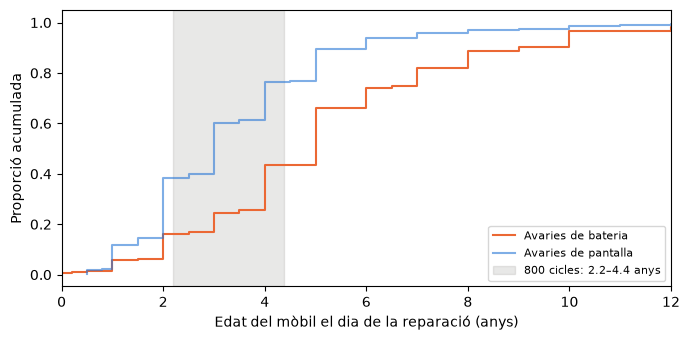

In [4]:
edats = np.sort(bateria["edat_neta"].to_numpy())
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.step(edats, np.arange(1, len(edats) + 1) / len(edats), where="post", color="#eb6834", label="Avaries de bateria")
ep = np.sort(pantalla["edat_neta"].to_numpy())
ax.step(ep, np.arange(1, len(ep) + 1) / len(ep), where="post", color="#2a78d6", alpha=0.6, label="Avaries de pantalla")
lo, hi = 800 / (1.0 * 365), 800 / (0.5 * 365)
ax.axvspan(lo, hi, color="#8f8e89", alpha=0.2, label=f"800 cicles: {lo:.1f}–{hi:.1f} anys")
ax.set_xlabel("Edat del mòbil el dia de la reparació (anys)")
ax.set_ylabel("Proporció acumulada"); ax.set_xlim(0, 12)
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

## Canvi en el temps

Abans i després del 2020: si les bateries arriben més velles a la reparació, és compatible amb bateries més duradores o amb gent que les aguanta més.

In [5]:
periodes = {"2013–2019": bateria[bateria["any_event"] <= 2019], "2021–2026": bateria[bateria["any_event"] >= 2021]}
pd.concat({k: mediana_ic(v) for k, v in periodes.items()}, axis=1).T

,n,mediana,ic_inf,ic_sup
2013–2019,66.0,4.0,3.5,4.0125
2021–2026,145.0,5.0,5.0,6.0000


## Per símptoma

Edat segons el símptoma descrit, sobre tots els registres amb edat (no només els classificats com a bateria).

In [6]:
s = comu.simptomes(dades["problem"])
amb_edat = pd.concat([dades, s], axis=1).dropna(subset=["edat_neta"])
pd.concat({nom: mediana_ic(amb_edat[amb_edat[nom]]) for nom in comu.SIMPTOMES}, axis=1).T

,n,mediana,ic_inf,ic_sup
no_carrega,66.0,4.0,3.0,5.0
dura_poc,23.0,5.0,3.5,6.0
no_sencen,54.0,4.5,3.0,5.0
inflada,11.0,6.5,5.0,8.0
